In [1]:
import sys
import pandas as pd
import numpy as np
import flaml
import lightgbm
import xgboost
import sklearn

print("Python version:", sys.version)
print("FLAML version:", flaml.__version__)
print("All libraries imported successfully!")

Python version: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
FLAML version: 2.7.0
All libraries imported successfully!


In [ ]:
import pandas as pd
#Loading the dataset
# Path to the diabetic patient dataset
RAW = "dataset_diabetes/diabetic_data.csv"

# Load the dataset
df = pd.read_csv(RAW, keep_default_na=False)

# Display dataset information
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five records
display(df.head())

Dataset shape: (101766, 50)
Number of rows: 101766
Number of columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# Explore the dataset
# Display all column names
print("Dataset columns:")
print(df.columns.tolist())

# Check the readmission categories
print("\nReadmission categories:")
print(df["readmitted"].value_counts())

# Check missing values represented by "?"
print("\nMissing values represented by '?':")
print((df == "?").sum().sort_values(ascending=False).head(15))

# Display summary statistics
display(df.describe())

Dataset columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Readmission categories:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Missing values represented by '?':
weight                 98569

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [4]:
# Create binary target variable
# 1 = Readmitted within 30 days
# 0 = Not readmitted within 30 days

df["target"] = (df["readmitted"] == "<30").astype(int)

print("Target distribution:")
print(df["target"].value_counts())

print("\n30-day readmission rate:")
print(f"{df['target'].mean() * 100:.2f}%")

Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64

30-day readmission rate:
11.16%


In [5]:
# Count all hospital encounters
n_all = len(df)

# Select emergency-department-sourced encounters
er = df[df["admission_source_id"] == 7].copy()

n_er = len(er)

# Exclude death and hospice discharge dispositions
excluded_codes = [11, 13, 14, 19, 20, 21]

excluded = er["discharge_disposition_id"].isin(excluded_codes)

n_excluded = int(excluded.sum())

# Remove excluded encounters
er = er[~excluded].copy()

# Summary of filtering
info = {
    "n_all": n_all,
    "n_er": n_er,
    "n_excluded": n_excluded,
    "n_model": len(er)
}

print("Dataset filtering summary:")
print(info)

print("\nFinal readmission rate:")
print(f"{er['target'].mean() * 100:.2f}%")

Dataset filtering summary:
{'n_all': 101766, 'n_er': 57494, 'n_excluded': 1644, 'n_model': 55850}

Final readmission rate:
11.98%


In [6]:
# Check final dataset
print("Final dataset shape:", er.shape)

print("\nReadmission distribution:")
print(er["target"].value_counts())

print("\nFirst five records:")
display(er.head())

Final dataset shape: (55850, 51)

Readmission distribution:
target
0    49160
1     6690
Name: count, dtype: int64

First five records:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,target
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,Steady,No,No,No,No,No,Ch,Yes,NO,0
7,63768,114882984,Caucasian,Male,[70-80),?,1,1,7,5,...,No,No,No,No,No,No,No,Yes,>30,0


In [7]:
# Function to group ICD-9 diagnosis codes

def icd_group(code):
    if pd.isna(code) or code == "?":
        return "Missing"

    c = str(code)

    if c.startswith(("V", "E")):
        return "Other"

    try:
        v = float(c)
    except:
        return "Other"

    if 390 <= v <= 459 or int(v) == 785:
        return "Circulatory"

    if 460 <= v <= 519 or int(v) == 786:
        return "Respiratory"

    if 520 <= v <= 579 or int(v) == 787:
        return "Digestive"

    if int(v) == 250:
        return "Diabetes"

    if 800 <= v <= 999:
        return "Injury"

    if 710 <= v <= 739:
        return "Musculoskeletal"

    if 580 <= v <= 629 or int(v) == 788:
        return "Genitourinary"

    if 140 <= v <= 239:
        return "Neoplasms"

    return "Other"


print("ICD-9 grouping function created successfully!")

ICD-9 grouping function created successfully!


In [8]:
# Discharge disposition categories

DISCH = {
    1: "Home",
    6: "Home health",
    8: "Home health",
    3: "SNF",
    4: "Other facility",
    5: "Other facility",
    22: "Rehab",
    23: "Other facility",
    24: "Other facility",
    2: "Other hospital",
    7: "Left AMA",
    9: "Other facility",
    15: "Other facility",
    16: "Other facility",
    17: "Other facility",
    30: "Other facility",
    27: "Other facility",
    28: "Other facility",
    29: "Other facility",
    12: "Other facility",
    10: "Other facility"
}

# Diabetes medications

MEDS = [
    "metformin", "repaglinide", "nateglinide",
    "chlorpropamide", "glimepiride", "acetohexamide",
    "glipizide", "glyburide", "tolbutamide",
    "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin",
    "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

print("Discharge categories:", len(DISCH))
print("Diabetes medications:", len(MEDS))

Discharge categories: 21
Diabetes medications: 23


In [9]:
# Create a dataframe for engineered features
X = pd.DataFrame(index=er.index)

# Patient demographics
X["age_mid"] = (
    er["age"].str.extract(r"\[(\d+)-")[0].astype(int) + 5
)

X["gender"] = er["gender"].replace({
    "Unknown/Invalid": "Female"
})

X["race"] = er["race"].replace("?", "Unknown")

# Admission type
X["admission_type"] = er["admission_type_id"].map({
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    7: "Trauma"
}).fillna("Unknown")

# Discharge group
X["discharge_group"] = (
    er["discharge_disposition_id"]
    .map(DISCH)
    .fillna("Other facility")
)

# Payer information
X["payer"] = er["payer_code"].replace("?", "Unknown")

# Medical specialty
top = er["medical_specialty"].value_counts().head(10).index

X["specialty"] = np.where(
    er["medical_specialty"].isin(top),
    er["medical_specialty"].replace("?", "Unknown"),
    "Other"
)

# Hospital utilization variables
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

for c in numeric_cols:
    X[c] = er[c]

print("Features created successfully!")
print("Feature matrix shape:", X.shape)

display(X.head())

Features created successfully!
Feature matrix shape: (55850, 15)


,age_mid,gender,race,admission_type,discharge_group,payer,specialty,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
1,15,Female,Caucasian,Emergency,Home,Unknown,Unknown,3,59,0,18,0,0,0,9
2,25,Female,AfricanAmerican,Emergency,Home,Unknown,Unknown,2,11,5,13,2,0,1,6
3,35,Male,Caucasian,Emergency,Home,Unknown,Unknown,2,44,1,16,0,0,0,7
4,45,Male,Caucasian,Emergency,Home,Unknown,Unknown,1,51,0,8,0,0,0,5
7,75,Male,Caucasian,Emergency,Home,Unknown,Unknown,5,73,0,12,0,0,0,8


In [10]:
# Total previous hospital visits
X["prior_visits_total"] = (
    er["number_outpatient"]
    + er["number_emergency"]
    + er["number_inpatient"]
)

# Previous emergency and inpatient visits
X["prior_acute_visits"] = (
    er["number_emergency"]
    + er["number_inpatient"]
)

# Whether patient has previously been hospitalized
X["any_prior_inpatient"] = (
    er["number_inpatient"] > 0
).astype(int)

# Laboratory tests per hospital day
X["labs_per_day"] = (
    er["num_lab_procedures"] / er["time_in_hospital"]
)

# Medications per hospital day
X["meds_per_day"] = (
    er["num_medications"] / er["time_in_hospital"]
)

# Combined procedures and medications
X["procedures_plus_meds"] = (
    er["num_procedures"] + er["num_medications"]
)

print("Feature matrix shape:", X.shape)

Feature matrix shape: (55850, 21)


In [11]:
# Group the three diagnosis columns
for i in (1, 2, 3):
    X[f"diag{i}_group"] = er[f"diag_{i}"].map(icd_group)

# Identify diabetes as the primary diagnosis
X["diabetes_primary"] = (
    X["diag1_group"] == "Diabetes"
).astype(int)

# Count circulatory diagnoses
X["n_circulatory_diag"] = sum(
    (X[f"diag{i}_group"] == "Circulatory").astype(int)
    for i in (1, 2, 3)
)

print("Feature matrix shape:", X.shape)

display(
    X[
        [
            "diag1_group",
            "diag2_group",
            "diag3_group",
            "diabetes_primary",
            "n_circulatory_diag"
        ]
    ].head()
)

Feature matrix shape: (55850, 26)


,diag1_group,diag2_group,diag3_group,diabetes_primary,n_circulatory_diag
1,Other,Diabetes,Other,0,0
2,Other,Diabetes,Other,0,0
3,Other,Diabetes,Circulatory,0,1
4,Neoplasms,Neoplasms,Diabetes,0,0
7,Circulatory,Respiratory,Diabetes,0,1


In [12]:
# Whether an A1C test was performed
X["a1c_measured"] = (
    ~er["A1Cresult"].isin(["None"])
).astype(int)

# A1C result category
X["a1c_result"] = er["A1Cresult"].replace({
    "None": "Not measured"
})

# High A1C without medication change
X["a1c_high_no_change"] = (
    er["A1Cresult"].isin([">7", ">8"])
    & (er["change"] == "No")
).astype(int)

# Glucose serum results
X["glucose_serum"] = er["max_glu_serum"].replace({
    "None": "Not measured"
})

print("Feature matrix shape:", X.shape)

Feature matrix shape: (55850, 30)


In [13]:
# Select diabetes medication columns
med = er[MEDS]

# Number of active diabetes medications
X["n_meds_active"] = (med != "No").sum(axis=1)

# Number of medications with dosage changes
X["n_meds_changed"] = med.isin(["Up", "Down"]).sum(axis=1)

# Insulin and metformin status
X["insulin"] = er["insulin"]
X["metformin"] = er["metformin"]

# Whether medication was changed
X["med_change"] = (er["change"] == "Ch").astype(int)

# Whether patient was prescribed diabetes medication
X["on_diabetes_med"] = (
    er["diabetesMed"] == "Yes"
).astype(int)

print("Feature matrix shape:", X.shape)

display(X.head())

Feature matrix shape: (55850, 36)


,age_mid,gender,race,admission_type,discharge_group,payer,specialty,time_in_hospital,num_lab_procedures,num_procedures,...,a1c_measured,a1c_result,a1c_high_no_change,glucose_serum,n_meds_active,n_meds_changed,insulin,metformin,med_change,on_diabetes_med
1,15,Female,Caucasian,Emergency,Home,Unknown,Unknown,3,59,0,...,0,Not measured,0,Not measured,1,1,Up,No,1,1
2,25,Female,AfricanAmerican,Emergency,Home,Unknown,Unknown,2,11,5,...,0,Not measured,0,Not measured,1,0,No,No,0,1
3,35,Male,Caucasian,Emergency,Home,Unknown,Unknown,2,44,1,...,0,Not measured,0,Not measured,1,1,Up,No,1,1
4,45,Male,Caucasian,Emergency,Home,Unknown,Unknown,1,51,0,...,0,Not measured,0,Not measured,2,0,Steady,No,1,1
7,75,Male,Caucasian,Emergency,Home,Unknown,Unknown,5,73,0,...,0,Not measured,0,Not measured,1,0,No,No,0,1


In [14]:
# Sort encounters chronologically using encounter ID
full = df[["encounter_id", "patient_nbr"]].sort_values(
    "encounter_id"
).copy()

# Count previous encounters recorded for each patient
full["prior_enc_in_data"] = (
    full.groupby("patient_nbr").cumcount()
)

# Add feature to modeling dataset
X["prior_enc_in_data"] = er["encounter_id"].map(
    full.set_index("encounter_id")["prior_enc_in_data"]
)

print("Feature matrix shape:", X.shape)

Feature matrix shape: (55850, 37)


In [15]:
import numpy as np
import pandas as pd
import time
import warnings

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

from flaml import AutoML

warnings.filterwarnings("ignore")

print("Modeling libraries imported successfully!")

Modeling libraries imported successfully!


In [17]:
# Define target variable
y = er["target"].copy()

# Define patient groups
groups = er["patient_nbr"].copy()

# Verify all variables exist
print("Features:", X.shape)
print("Target:", y.shape)
print("Patient groups:", groups.shape)

Features: (55850, 37)
Target: (55850,)
Patient groups: (55850,)


In [18]:
# Split data by patient to avoid patient overlap
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

tr_i, te_i = next(gss.split(X, y, groups))

# Training dataset
Xtr = X.iloc[tr_i]
ytr = y.iloc[tr_i]
gtr = groups.iloc[tr_i]

# Testing dataset
Xte = X.iloc[te_i]
yte = y.iloc[te_i]

# Check patient overlap
train_patients = set(gtr)
test_patients = set(groups.iloc[te_i])

print("Training encounters:", len(Xtr))
print("Testing encounters:", len(Xte))
print("Training readmission rate:", f"{ytr.mean()*100:.2f}%")
print("Testing readmission rate:", f"{yte.mean()*100:.2f}%")
print("Patients appearing in both sets:", len(train_patients & test_patients))

Training encounters: 44693
Testing encounters: 11157
Training readmission rate: 12.03%
Testing readmission rate: 11.77%
Patients appearing in both sets: 0


In [19]:
# Baseline features from the original project
base_cols = [
    "age_mid",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
    "a1c_measured"
]

# Create logistic regression pipeline
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train baseline model
lr.fit(Xtr[base_cols], ytr)

# Predict readmission probabilities
p_base = lr.predict_proba(Xte[base_cols])[:, 1]

print("Baseline logistic regression trained successfully!")

Baseline logistic regression trained successfully!


In [20]:
# Calculate baseline performance
baseline_auc = roc_auc_score(yte, p_base)
baseline_ap = average_precision_score(yte, p_base)

# Store results for later comparison
res = {}

res["Baseline: logistic regression, original variables"] = (
    baseline_auc,
    baseline_ap,
    p_base
)

print("BASELINE LOGISTIC REGRESSION RESULTS")
print("------------------------------------")
print(f"ROC AUC: {baseline_auc:.4f}")
print(f"Average Precision: {baseline_ap:.4f}")
print(f"Test readmission rate: {yte.mean():.4f}")

BASELINE LOGISTIC REGRESSION RESULTS
------------------------------------
ROC AUC: 0.6388
Average Precision: 0.2087
Test readmission rate: 0.1177


In [22]:
# Prepare training and testing data for FLAML
# Exclude prior_enc_in_data to reduce potential data leakage

Xtr_automl = Xtr.drop(
    columns=["prior_enc_in_data"],
    errors="ignore"
).copy()

Xte_automl = Xte.drop(
    columns=["prior_enc_in_data"],
    errors="ignore"
).copy()

# Verify the datasets
print("FLAML training dataset:", Xtr_automl.shape)
print("FLAML testing dataset:", Xte_automl.shape)
print("Number of features:", Xtr_automl.shape[1])

FLAML training dataset: (44693, 36)
FLAML testing dataset: (11157, 36)
Number of features: 36


In [23]:
# Initialize FLAML AutoML
automl = AutoML()

# Patient-level cross-validation
from sklearn.model_selection import GroupKFold

group_cv = GroupKFold(n_splits=4)

start_time = time.time()

automl.fit(
    X_train=Xtr_automl,
    y_train=ytr,
    task="classification",
    metric="roc_auc",
    time_budget=420,
    estimator_list=[
        "lgbm",
        "xgboost",
        "rf",
        "extra_tree",
        "lrl1"
    ],
    eval_method="cv",
    split_type=group_cv,
    groups=gtr.to_numpy(),
    n_splits=4,
    seed=42,
    verbose=1,
    log_file_name="flaml.log"
)

print("\nFLAML training completed!")
print("Training time:", round(time.time() - start_time, 2), "seconds")
print("Best estimator:", automl.best_estimator)
print("Best configuration:", automl.best_config)


FLAML training completed!
Training time: 428.23 seconds
Best estimator: xgboost
Best configuration: {'n_estimators': 81, 'max_leaves': 4, 'min_child_weight': np.float64(1.1981922815116113), 'learning_rate': np.float64(0.22072454681883577), 'subsample': np.float64(0.744896312031056), 'colsample_bylevel': np.float64(0.861257057737071), 'colsample_bytree': np.float64(0.8438144153658806), 'reg_alpha': np.float64(0.0029695775514540367), 'reg_lambda': np.float64(78.15314864016963)}


In [24]:
# Predict using the best FLAML model
p_aml = automl.predict_proba(Xte_automl)[:, 1]

# Calculate evaluation metrics
automl_auc = roc_auc_score(yte, p_aml)
automl_ap = average_precision_score(yte, p_aml)

# Store results
res["AutoML (FLAML) on engineered features"] = (
    automl_auc,
    automl_ap,
    p_aml
)

# Compare models
comparison = pd.DataFrame({
    "Model": ["Baseline Logistic Regression", "FLAML AutoML"],
    "ROC AUC": [baseline_auc, automl_auc],
    "Average Precision": [baseline_ap, automl_ap]
})

display(comparison.round(4))

print("ROC AUC improvement:", round(automl_auc - baseline_auc, 4))
print("Average Precision improvement:", round(automl_ap - baseline_ap, 4))

,Model,ROC AUC,Average Precision
0,Baseline Logistic Regression,0.6388,0.2087
1,FLAML AutoML,0.6591,0.2209


ROC AUC improvement: 0.0202
Average Precision improvement: 0.0121


In [25]:
from sklearn.metrics import confusion_matrix

# Convert target and predictions to NumPy arrays
y_test = yte.to_numpy()
p = p_aml
pb = p_base

def at_top(probabilities, fraction):
    threshold = np.quantile(probabilities, 1 - fraction)

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Targeted %": fraction * 100,
        "Threshold": round(float(threshold), 4),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Precision": round(tp / (tp + fp), 4),
        "Recall": round(tp / (tp + fn), 4),
        "Specificity": round(tn / (tn + fp), 4),
        "Lift": round(
            (tp / (tp + fp)) / y_test.mean(), 4
        )
    }

# Evaluate both models
results = []

for fraction in [0.10, 0.20, 0.30]:
    baseline_result = at_top(pb, fraction)
    baseline_result["Model"] = "Logistic Regression"

    automl_result = at_top(p, fraction)
    automl_result["Model"] = "FLAML AutoML"

    results.extend([baseline_result, automl_result])

evaluation_df = pd.DataFrame(results)

display(evaluation_df)

,Targeted %,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,Lift,Model
0,10.0,0.1735,284,832,9012,1029,0.2545,0.2163,0.9155,2.1624,Logistic Regression
1,10.0,0.2008,296,820,9024,1017,0.2652,0.2254,0.9167,2.2538,FLAML AutoML
2,20.0,0.1402,436,1796,8048,877,0.1953,0.3321,0.8176,1.6599,Logistic Regression
3,20.0,0.1627,488,1744,8100,825,0.2186,0.3717,0.8228,1.8578,FLAML AutoML
4,30.0,0.1240,606,2741,7103,707,0.1811,0.4615,0.7216,1.5385,Logistic Regression
5,30.0,0.1403,654,2693,7151,659,0.1954,0.4981,0.7264,1.6604,FLAML AutoML


In [26]:
# Bootstrap confidence interval for FLAML ROC AUC
rng = np.random.default_rng(0)

auc_scores = []

for _ in range(300):
    indices = rng.integers(0, len(y_test), len(y_test))

    # Skip samples containing only one class
    if len(np.unique(y_test[indices])) < 2:
        continue

    auc = roc_auc_score(
        y_test[indices],
        p[indices]
    )

    auc_scores.append(auc)

lower, upper = np.percentile(auc_scores, [2.5, 97.5])

print("FLAML ROC AUC:", round(roc_auc_score(y_test, p), 4))
print("95% Bootstrap CI:", round(lower, 4), "-", round(upper, 4))

FLAML ROC AUC: 0.6591
95% Bootstrap CI: 0.6422 - 0.6754


In [27]:
# Compare predicted and actual readmission rates
d = pd.DataFrame({
    "predicted_probability": p,
    "actual_readmission": y_test
})

# Divide patients into 10 risk groups
d["risk_decile"] = pd.qcut(
    d["predicted_probability"].rank(method="first"),
    10,
    labels=False
) + 1

calibration = d.groupby("risk_decile").agg(
    predicted_rate=("predicted_probability", "mean"),
    actual_rate=("actual_readmission", "mean"),
    patients=("actual_readmission", "size")
)

print("Calibration by risk decile:")
display(calibration.round(4)) 

Calibration by risk decile:


,predicted_rate,actual_rate,patients
risk_decile,,,
1,0.0480,0.0421,1116
2,0.0607,0.0690,1116
3,0.0715,0.0726,1115
4,0.0840,0.0833,1116
5,0.1005,0.0869,1116
6,0.1161,0.1175,1115
7,0.1316,0.1192,1116
8,0.1510,0.1489,1115
9,0.1798,0.1720,1116


In [29]:
# Evaluate ROC AUC by gender and race
# Works with both string and categorical columns

for column in ["gender", "race"]:
    print(f"\nPerformance by {column}:")

    for category in Xte[column].dropna().unique():

        mask = (Xte[column] == category).to_numpy()

        # Evaluate only sufficiently large groups
        if mask.sum() > 500 and y_test[mask].sum() > 30:

            auc = roc_auc_score(
                y_test[mask],
                p[mask]
            )

            print(
                category,
                "| Patients:", mask.sum(),
                "| ROC AUC:", round(auc, 4)
            )


# Evaluate ROC AUC by age group
age_groups = pd.cut(
    Xte["age_mid"],
    bins=[0, 50, 70, 100]
)

print("\nPerformance by age group:")

for category in age_groups.cat.categories:

    mask = (age_groups == category).to_numpy()

    if mask.sum() > 0 and len(np.unique(y_test[mask])) == 2:

        auc = roc_auc_score(
            y_test[mask],
            p[mask]
        )

        print(
            category,
            "| Patients:", mask.sum(),
            "| ROC AUC:", round(auc, 4)
        )


Performance by gender:
Female | Patients: 6078 | ROC AUC: 0.6574
Male | Patients: 5079 | ROC AUC: 0.6601

Performance by race:
AfricanAmerican | Patients: 2243 | ROC AUC: 0.6417
Caucasian | Patients: 8193 | ROC AUC: 0.6604

Performance by age group:
(0, 50] | Patients: 1774 | ROC AUC: 0.747
(50, 70] | Patients: 4237 | ROC AUC: 0.6768
(70, 100] | Patients: 5146 | ROC AUC: 0.6016


In [30]:
# Financial benefit analysis
# Scenario: 10,000 hospital encounters

def financial_scenario(
    n=10000,
    effectiveness=0.15,
    readmission_cost=15200,
    intervention_cost=250,
    target_fraction=0.20,
    recall=0.3717
):
    # Expected number of readmissions
    expected_readmissions = n * y_test.mean()

    # Patients selected for intervention
    patients_flagged = n * target_fraction

    # Actual readmissions among flagged patients
    true_positives = expected_readmissions * recall

    # Readmissions potentially prevented
    avoided_readmissions = true_positives * effectiveness

    # Financial calculations
    gross_savings = avoided_readmissions * readmission_cost
    intervention_expenses = patients_flagged * intervention_cost
    net_savings = gross_savings - intervention_expenses

    return {
        "Patients": n,
        "Expected Readmissions": round(expected_readmissions),
        "Patients Flagged": round(patients_flagged),
        "True Positives": round(true_positives),
        "Avoided Readmissions": round(avoided_readmissions, 1),
        "Gross Savings ($)": round(gross_savings, 2),
        "Intervention Costs ($)": round(intervention_expenses, 2),
        "Net Savings ($)": round(net_savings, 2)
    }


scenario = financial_scenario()

display(pd.DataFrame([scenario]))

,Patients,Expected Readmissions,Patients Flagged,True Positives,Avoided Readmissions,Gross Savings ($),Intervention Costs ($),Net Savings ($)
0,10000,1177,2000,437,65.6,997343.36,500000.0,497343.36


In [31]:
# Compare intervention strategies

prevalence = y_test.mean()
model_recall = at_top(p, 0.20)["Recall"]

strategies = {
    "FLAML Top 20%": {
        "fraction": 0.20,
        "recall": model_recall
    },
    "Random 20%": {
        "fraction": 0.20,
        "recall": 0.20
    },
    "Treat Everyone": {
        "fraction": 1.00,
        "recall": 1.00
    }
}

comparison_results = []

for name, settings in strategies.items():

    result = financial_scenario(
        n=10000,
        effectiveness=0.15,
        readmission_cost=15200,
        intervention_cost=250,
        target_fraction=settings["fraction"],
        recall=settings["recall"]
    )

    result["Strategy"] = name
    comparison_results.append(result)

strategy_df = pd.DataFrame(comparison_results)

display(
    strategy_df[
        [
            "Strategy",
            "Patients Flagged",
            "Avoided Readmissions",
            "Gross Savings ($)",
            "Intervention Costs ($)",
            "Net Savings ($)"
        ]
    ].round(2)
)

,Strategy,Patients Flagged,Avoided Readmissions,Gross Savings ($),Intervention Costs ($),Net Savings ($)
0,FLAML Top 20%,2000,65.6,997343.36,500000.0,497343.36
1,Random 20%,2000,35.3,536638.88,500000.0,36638.88
2,Treat Everyone,10000,176.5,2683194.41,2500000.0,183194.41


In [32]:
# Sensitivity analysis for FLAML Top 20%

sensitivity_results = []

for effectiveness in [0.10, 0.15, 0.20, 0.25]:

    for readmission_cost in [10000, 15200]:

        result = financial_scenario(
            n=10000,
            effectiveness=effectiveness,
            readmission_cost=readmission_cost,
            intervention_cost=250,
            target_fraction=0.20,
            recall=model_recall
        )

        sensitivity_results.append({
            "Intervention Effectiveness": f"{effectiveness:.0%}",
            "Readmission Cost ($)": readmission_cost,
            "Avoided Readmissions": result["Avoided Readmissions"],
            "Net Savings ($)": result["Net Savings ($)"]
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df)

,Intervention Effectiveness,Readmission Cost ($),Avoided Readmissions,Net Savings ($)
0,10%,10000,43.7,-62568.70
1,10%,15200,43.7,164895.57
2,15%,10000,65.6,156146.95
3,15%,15200,65.6,497343.36
4,20%,10000,87.5,374862.60
5,20%,15200,87.5,829791.15
6,25%,10000,109.4,593578.25
7,25%,15200,109.4,1162238.94


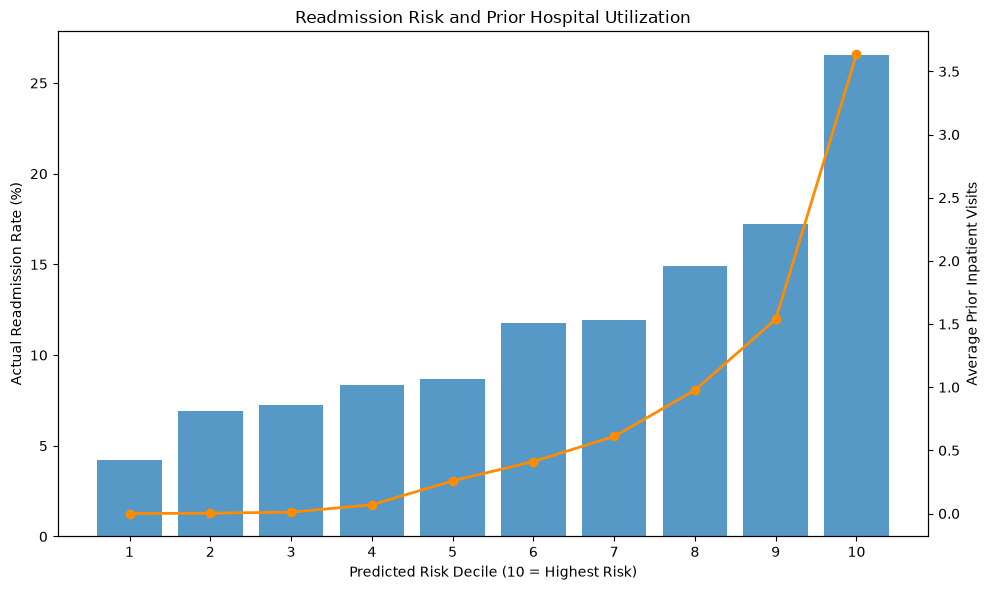

Figure 1 saved as fig1.png


In [33]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Build risk-decile dataset
chart_data = pd.DataFrame({
    "Predicted Risk": p,
    "Actual Readmission": y_test,
    "Prior Inpatient Visits": Xte["number_inpatient"].to_numpy()
})

chart_data["Risk Decile"] = pd.qcut(
    chart_data["Predicted Risk"].rank(method="first"),
    10,
    labels=False
) + 1

decile_summary = chart_data.groupby("Risk Decile").agg(
    Readmission_Rate=("Actual Readmission", "mean"),
    Avg_Prior_Inpatient=("Prior Inpatient Visits", "mean")
)

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.bar(
    decile_summary.index,
    decile_summary["Readmission_Rate"] * 100,
    alpha=0.75,
    label="Actual Readmission Rate"
)

ax1.set_xlabel("Predicted Risk Decile (10 = Highest Risk)")
ax1.set_ylabel("Actual Readmission Rate (%)")
ax1.set_xticks(range(1, 11))

ax2 = ax1.twinx()

ax2.plot(
    decile_summary.index,
    decile_summary["Avg_Prior_Inpatient"],
    marker="o",
    linewidth=2,
    color="darkorange",
    label="Average Prior Inpatient Visits"
)

ax2.set_ylabel("Average Prior Inpatient Visits")

plt.title("Readmission Risk and Prior Hospital Utilization")
fig.tight_layout()

plt.savefig("fig1.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure 1 saved as fig1.png")

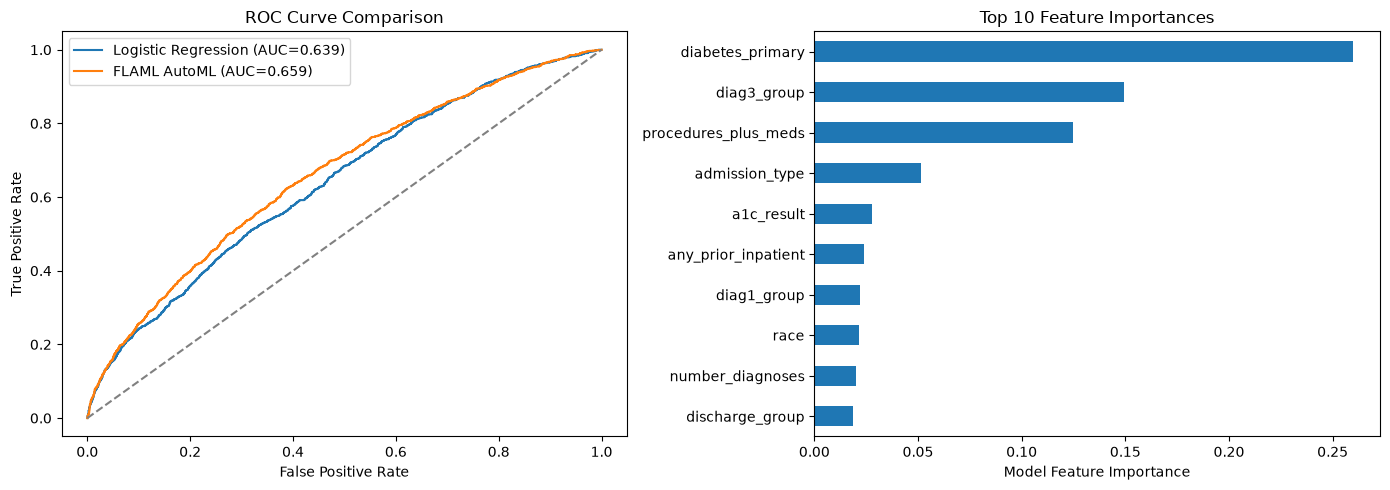

Figure 2 saved as fig2.png
Best FLAML estimator: xgboost


In [34]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC curves
fpr_base, tpr_base, _ = roc_curve(y_test, pb)
fpr_aml, tpr_aml, _ = roc_curve(y_test, p)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    fpr_base, tpr_base,
    label=f"Logistic Regression (AUC={roc_auc_score(y_test, pb):.3f})"
)

axes[0].plot(
    fpr_aml, tpr_aml,
    label=f"FLAML AutoML (AUC={roc_auc_score(y_test, p):.3f})"
)

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve Comparison")
axes[0].legend()

# Feature importance, if available
best_model = automl.model.estimator

if hasattr(best_model, "feature_importances_"):

    importance = pd.Series(
        best_model.feature_importances_,
        index=Xtr_automl.columns
    ).sort_values(ascending=False).head(10)

    importance.sort_values().plot(
        kind="barh",
        ax=axes[1]
    )

    axes[1].set_title("Top 10 Feature Importances")
    axes[1].set_xlabel("Model Feature Importance")

else:
    axes[1].text(
        0.5, 0.5,
        "Feature importance not available\nfor the selected estimator",
        ha="center",
        va="center"
    )
    axes[1].set_axis_off()

fig.tight_layout()

plt.savefig("fig2.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figure 2 saved as fig2.png")
print("Best FLAML estimator:", automl.best_estimator)